# Exercises XP Gold: Student Notebook

This notebook is guided to complete the execices on the plateforme. 
For each exercise, the **Instructions** are guided and some parts are already coded, and the **Guidance** explains exactly what you must do in complete sentences.

## How to run in Colab
1. Open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → choose this file.
2. Run the cells from top to bottom (Shift+Enter runs one cell).
3. No external dataset is needed: the numbers and the example charts are created in the notebook.


## What will you create
- calculation sheets for metrics like Accuracy, Precision, Recall, and F1-Score based on given confusion matrix values.
- develop strategic proposals that address specific challenges posed by these issues.
- build frameworks for evaluating classification models in different scenarios, especially focusing on the impact of class imbalance and the role of threshold tuning.

## What will you learn
- Understand and interpret the confusion matrix in different scenarios.
- Understand the trade-offs between different evaluation metrics.
- Explore the concepts of cross-validation and learning curves.

## Exercise 1 : Analyzing Confusion Matrix

### Instructions
Imagine you have a dataset for a binary classification problem, such as email spam detection, where emails are classified as either ‘Spam’ or ‘Not Spam’. You are provided with the confusion matrix results of a classifier.
- Define in your own words what True Positives, True Negatives, False Positives, and False Negatives mean in the context of this email spam detection problem.
- Given a confusion matrix with specific values for TP, TN, FP, FN, calculate the Accuracy, Precision, Recall, and F1-Score.
- Discuss how the classifier’s performance would change with a higher number of False Positives compared to False Negatives, and vice versa.

### Guidance
- You will start by writing complete sentences that define True Positives, True Negatives, False Positives, and False Negatives using the spam example. 
- You will then run the prefilled code to enter TP, TN, FP, and FN and compute the four metrics. 
- You will also generate a calculation sheet that tabulates the metrics so you can export or present the results. 
- You will finish by writing a paragraph that explains how increasing False Positives versus increasing False Negatives changes the behavior and implications of the classifier.

In [1]:

# This piece of code is already prefilled, run it to execute it and see the results.
# Enter the confusion matrix values as integers and execute the cell to compute the metrics.

# TP: predicted Spam and actually Spam
# TN: predicted Not Spam and actually Not Spam
# FP: predicted Spam but actually Not Spam
# FN: predicted Not Spam but actually Spam

TP = 50   # replace with your value
TN = 920  # replace with your value
FP = 30   # replace with your value
FN = 20   # replace with your value

total = TP + TN + FP + FN
accuracy  = (TP + TN) / total if total else 0.0
precision = TP / (TP + FP) if (TP + FP) else 0.0
recall    = TP / (TP + FN) if (TP + FN) else 0.0
f1_score  = (2 * precision * recall / (precision + recall)) if (precision + recall) else 0.0

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1_score, 4))

Accuracy: 0.951
Precision: 0.625
Recall: 0.7143
F1-Score: 0.6667


In [2]:

# This piece of code is already prefilled, run it to execute it and see the results.
# It builds a calculation sheet as a small table and saves it to CSV for reporting.

import pandas as pd

calc_sheet = pd.DataFrame([{
    "TP": TP, "TN": TN, "FP": FP, "FN": FN,
    "Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1-Score": f1_score
}])

print(calc_sheet)
csv_path = "confusion_metrics_sheet.csv"
calc_sheet.to_csv(csv_path, index=False)
print("Saved CSV to:", csv_path)

   TP   TN  FP  FN  Accuracy  Precision    Recall  F1-Score
0  50  920  30  20   0.95098      0.625  0.714286  0.666667
Saved CSV to: confusion_metrics_sheet.csv


### Your written analysis

I chose these example values for a spam filter: **TP = 50**, **TN = 920**, **FP = 30** and **FN = 20**. That means the filter saw 1020 emails, of which 70 were really spam and 950 were really not spam.

In this spam-detection problem I use the words this way:

- A **True Positive (TP)** is an email that the model called Spam and that really is spam. The filter did the right thing and hid a junk message.
- A **True Negative (TN)** is an email that the model called Not Spam and that really is a normal email. The filter correctly left it in the inbox.
- A **False Positive (FP)** is an email that the model called Spam but that was actually a real message. This is a false alarm: an important email may now be hidden in the spam folder.
- A **False Negative (FN)** is an email that the model called Not Spam but that was actually spam. The filter missed it, so junk (or even a phishing message) reaches the inbox.

The code above computes the four metrics from these counts:

- Accuracy = (TP + TN) / total = 970 / 1020 ≈ **0.9510**. About 95% of all emails are classified correctly.
- Precision = TP / (TP + FP) = 50 / 80 = **0.6250**. When the model says “spam”, it is right 62.5% of the time.
- Recall = TP / (TP + FN) = 50 / 70 ≈ **0.7143**. The model catches about 71% of the real spam.
- F1-Score is the balance between precision and recall, about **0.6667**.

Accuracy looks high mainly because most emails are not spam, so the many true negatives help the score. Precision and recall tell a more honest story.

If **False Positives** go up, more real emails are sent to the spam folder. Precision falls, and a user might miss a message from work or from a bank. If **False Negatives** go up, more spam reaches the inbox. Recall falls, and the user sees more junk or more dangerous messages. In spam filtering, too many false positives can be worse than a few false negatives, because hiding a real email is often more costly than letting one extra spam message through. That is why I look at precision and recall together, not only at accuracy.


## Exercise 2 : Evaluating Trade-offs in Metrics

### Instructions
Consider a medical diagnosis application where a model predicts whether patients have a certain disease.
- Explain why high recall is more important than high precision in this medical diagnosis context.
- Describe a scenario where precision becomes more important than recall.
- Discuss the potential consequences of focusing solely on improving accuracy in imbalanced datasets.

### Guidance
- You will write one paragraph that explains why high recall is often prioritized in disease screening and why missing positive cases is risky. 
- You will then write one paragraph that presents a realistic scenario where precision is more important than recall and you will justify your choice. 
- You will close with one paragraph that explains why accuracy can be misleading on imbalanced datasets and what risks this creates for decisions.

### Your answer

In a medical diagnosis model, **high recall is more important than high precision** because the positive class is “this patient has the disease”. A false negative means the model misses a sick person. That person may not get treatment in time, and the health cost can be very serious. A false positive means the model raises a false alarm. That is unpleasant and it can lead to extra tests, but those extra tests can still correct the mistake. In screening, I would rather check some healthy people twice than miss people who are really ill.

Precision becomes more important than recall in a situation where a false alarm is very costly or harmful. One example is a model that blocks a customer’s bank account because it thinks a payment is fraud. If precision is low, many honest customers are locked out of their money. Another example is a spam filter, or a model that recommends a risky, expensive surgery: I want to be quite sure before I act, even if I miss a few true cases that can be caught later by another check.

Focusing only on **accuracy** is dangerous when the dataset is imbalanced. If only a small share of patients have the disease, a model that always predicts “no disease” can get a very high accuracy and still find nobody who is sick. The hospital would then believe the model is excellent, while it is actually useless for diagnosis. That is why I also look at precision, recall, F1-score, the confusion matrix and, when the positive class is rare, the precision-recall curve.


## Exercise 3 : Understanding Cross-Validation and Learning Curves

### Instructions
You are working on a project with a large dataset that involves predicting housing prices based on various features.
- Explain the difference between K-Fold Cross-Validation and Stratified K-Fold Cross-Validation. Which one would you choose for this task and why?
- Describe what learning curves are and how they can help in understanding the performance of your model.
- Discuss the implications of underfitting and overfitting as observed from learning curves, and how you might address these issues.

### Guidance
- You will begin by explaining the difference between K-Fold and Stratified K-Fold in complete sentences and you will state which approach is suitable for this regression task and why. 
- You will then run the prefilled code to generate a learning curve example using synthetic regression data. 
- You will finally write a paragraph that interprets the learning curves, explains signs of underfitting and overfitting, and proposes practical actions to address each issue.

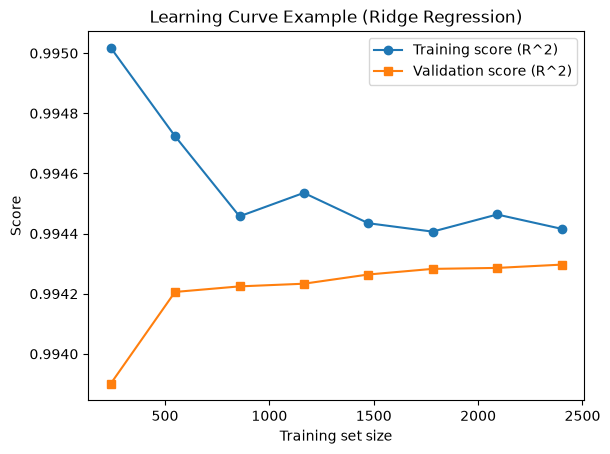

In [3]:

# This piece of code is already prefilled, run it to execute it and see the results.
# It generates a learning curve for a regression model using synthetic data.

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import learning_curve, KFold
from sklearn.linear_model import Ridge

X, y = make_regression(n_samples=3000, n_features=20, noise=15.0, random_state=42)
estimator = Ridge(alpha=1.0, random_state=42)

cv = KFold(n_splits=5, shuffle=True, random_state=42)
train_sizes, train_scores, valid_scores = learning_curve(
    estimator, X, y, cv=cv, scoring="r2", train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=None, shuffle=True, random_state=42
)

train_mean = np.mean(train_scores, axis=1)
valid_mean = np.mean(valid_scores, axis=1)

import matplotlib.pyplot as plt
plt.figure()
plt.plot(train_sizes, train_mean, marker="o", label="Training score (R^2)")
plt.plot(train_sizes, valid_mean, marker="s", label="Validation score (R^2)")
plt.xlabel("Training set size")
plt.ylabel("Score")
plt.title("Learning Curve Example (Ridge Regression)")
plt.legend()
plt.show()

### Your interpretation

This project predicts **housing prices**, which are a continuous number, so it is a **regression** task.

**K-Fold cross-validation** splits the data into K equal parts (folds). The model trains on K − 1 folds and validates on the remaining fold, then repeats this so every fold is used once as validation. The final score is the average of the K scores. **Stratified K-Fold** does the same thing but also keeps the same class proportions in every fold. Stratified K-Fold is designed for **classification**, where the target is a label such as yes/no. For housing prices I would choose **ordinary K-Fold**, because the target is not made of classes. (If the prices were extremely skewed I could bin them and then stratify, but the standard choice for this regression task is K-Fold.)

A **learning curve** plots the training score and the validation score as the training set grows. It helps me see whether the model needs more data, whether it is too simple, or whether it is memorising the training set.

In the example chart I generated with Ridge regression on synthetic data, both the training R² and the validation R² are very high (about **0.994**) and the gap between them is tiny (about **0.001**). The two lines stay close as more data is added. This pattern means the model fits the data well and **generalises well**: it is not clearly underfitting and it is not clearly overfitting.

If both curves were **low and close together**, that would be **underfitting**: the model is too simple to capture the pattern. I would try a more flexible model, add useful features, or reduce too-strong regularisation (for Ridge, I would try a smaller alpha).

If the **training score were high but the validation score were much lower**, that would be **overfitting**: the model memorises the training rows and fails on new rows. I would then simplify the model, use stronger regularisation (a larger alpha for Ridge), collect more training data, or drop noisy features.

The learning curve is therefore a practical diagnostic: it does not only give one score, it shows me *how* the model is failing so I know which fix to try.


## Exercise 4 : Impact of Class Imbalance on Model Evaluation

### Instructions
Imagine you are working on a dataset for detecting a rare disease where only 2% of the instances are positive cases (have the disease).
- Explain why using accuracy as an evaluation metric might be misleading in this scenario.
- Discuss the importance of precision and recall in the context of this imbalanced dataset.
- Propose strategies you could use to more effectively evaluate and improve the model’s performance in this scenario, considering the imbalance in the dataset.

### Guidance
- You will write one paragraph that explains why a naive classifier can reach high accuracy by predicting the majority class in a highly imbalanced dataset. 
- You will then write one paragraph that explains the roles of precision and recall in rare-disease detection and how they reflect different types of errors. 
- You will finish with one paragraph that lists strategies to evaluate and improve performance, including stratified splits, class weights, resampling, appropriate metrics, and calibration.

In [4]:

# This piece of code is already prefilled, run it to execute it and see the results.
# It creates a simple illustration of class imbalance and baseline accuracy.

from collections import Counter
import numpy as np

y = np.array([1]*20 + [0]*980)  # 2 percent positives
counter = Counter(y)
majority_class = counter.most_common(1)[0][0]
baseline_accuracy = (y == majority_class).mean()

print("Class distribution:", counter)
print("Majority-class baseline accuracy:", round(baseline_accuracy, 4))
print("Reflect on why this accuracy is high yet uninformative for rare-disease detection.")

Class distribution: Counter({np.int64(0): 980, np.int64(1): 20})
Majority-class baseline accuracy: 0.98
Reflect on why this accuracy is high yet uninformative for rare-disease detection.


### Your answer

If only **2%** of the rows are positive (the person has the rare disease), a model that always predicts “no disease” is already correct for 98% of the rows. The prefilled example above shows this: 20 positives and 980 negatives give a majority-class accuracy of **0.98**. That number looks excellent, but the model would find **zero** sick patients. Accuracy is therefore misleading here, because the many easy negatives hide the mistakes that actually matter.

**Precision** answers: “When the model says this person is sick, how often is that true?” Low precision means many healthy people are flagged. They may become very worried or go through extra tests they do not need. **Recall** answers: “Of all the people who really are sick, how many did we catch?” Low recall means we are missing real patients, which is dangerous in medicine. I need both numbers (and often the F1-score, which balances them) because they describe two different kinds of error.

To evaluate and improve the model on this imbalanced data I would do several things. I would use a **stratified** train/test split and stratified cross-validation so the rare positive class appears in every fold. I would give the positive class a higher **class weight**, or I would resample the training set (repeat some sick cases or reduce some healthy cases), but I would never change the test set. I would report precision, recall, F1-score, the confusion matrix, ROC-AUC and especially **PR-AUC**, which is more informative when positives are rare. I would also **tune the decision threshold** so that I catch more of the sick patients, and I would check that the predicted probabilities are reasonably calibrated before a doctor uses them.


## Exercise 5 : Role of Threshold Tuning in Classification Models

### Instructions
You are evaluating a binary classification model that predicts whether a bank’s client will default on a loan. The model outputs a probability score between 0 and 1.
- Describe how changing the threshold for classifying a positive case (default) from 0.5 to 0.7 might affect the model’s precision and recall.
- Discuss the potential consequences of setting the threshold too high or too low in the context of loan default prediction.
- Explain how ROC (Receiver Operating Characteristic) curves and AUC (Area Under the Curve) can assist in finding the optimal threshold.

### Guidance
- You will write one paragraph that explains how increasing the threshold generally increases precision and decreases recall, while decreasing the threshold usually does the opposite. 
- You will then write one paragraph that explains practical consequences of the threshold choice in loan default prediction for both false positives and false negatives. 
- You will finally run the prefilled code to see how precision and recall change with the threshold and how the ROC curve and AUC summarize trade-offs.

Threshold  Precision  Recall
      0.1        0.4     1.0
      0.2        0.5     1.0
      0.3      0.727     1.0
      0.4      0.889     1.0
      0.5        1.0     1.0
      0.6        1.0     1.0
      0.7        1.0   0.875
      0.8        1.0     0.5
      0.9        1.0   0.125


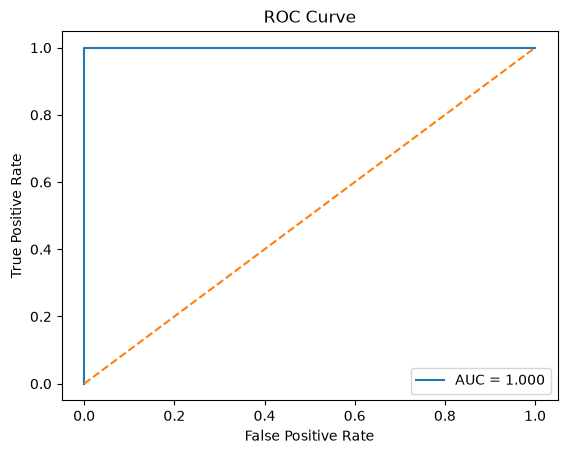

In [5]:

# This piece of code is already prefilled, run it to execute it and see the results.
# It evaluates precision and recall across thresholds and plots an ROC curve.

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, roc_curve, auc

# Example placeholders. Replace with your own true labels and predicted probabilities if available.
y_true = np.array([0,1,0,1,0,1,0,0,1,0,1,0,0,1,0,0,1,0,1,0])
y_pred_proba = np.array([0.10,0.82,0.12,0.65,0.28,0.73,0.33,0.21,0.88,0.19,0.77,0.40,0.27,0.91,0.31,0.18,0.79,0.29,0.84,0.22])

thresholds = np.linspace(0.1, 0.9, 9)
rows = []
for t in thresholds:
    y_pred = (y_pred_proba >= t).astype(int)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec  = recall_score(y_true, y_pred, zero_division=0)
    rows.append((round(t,2), round(prec,3), round(rec,3)))

print("Threshold  Precision  Recall")
for r in rows:
    print(f"{r[0]:>9}  {r[1]:>9}  {r[2]:>6}")

fpr, tpr, roc_th = roc_curve(y_true, y_pred_proba)
roc_auc = auc(fpr, tpr)

import matplotlib.pyplot as plt
plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

### Please provide answers to questions above

The model outputs a probability between 0 and 1, and I turn that probability into a yes/no decision with a **threshold**. If I raise the threshold from **0.5 to 0.7**, the model only calls “default” when it is more confident. In general this **increases precision** (the defaults I flag are more often real defaults) and **decreases recall** (I miss more of the people who will actually default). In the small example above, precision stays at 1.00 and recall falls from 1.00 at threshold 0.5 to **0.875** at threshold 0.7. The example data is unusually clean, but it still shows the same trade-off: a higher bar catches fewer positives.

If I set the threshold **too high**, I will miss many defaulters (more false negatives). The bank then approves loans that are not repaid and loses money. If I set the threshold **too low**, I will flag too many good clients as risky (more false positives). The bank then rejects people who would have repaid, loses business and may treat customers unfairly. The “best” threshold depends on how costly each error is for the bank, not on a default value of 0.5.

A **ROC curve** plots the true positive rate against the false positive rate at many thresholds. It shows the whole trade-off in one picture. **AUC** (area under that curve) summarises how well the model ranks defaulters above non-defaulters: 1.0 is a perfect ranking and 0.5 is no better than chance. The example above has AUC = 1.0 because the placeholder scores already separate the two classes perfectly; on real loan data I would expect a lower AUC. AUC helps me compare models, but I still choose the operating threshold by looking at precision, recall and the business cost of each type of error.
